# The ≈860 d peak of HARPS-N − SunSim: HARPS-N and SunSim alone, without and with the offsets, harmonics

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sunsim import local_path, observations as obs
from sunsim.residuals import ResidualAnalysis

SIM_RV = os.path.join(local_path('personal_data'), 'rv-15.txt')
ORIGIN = '2015-07-18'
FIRST, LAST = '2015-07-18', '2024-01-28'
YEAR = 365.25
P_PEAK = 861.0                       # [d] highest peak of HARPS-N - SunSim with the 21 offsets (injection_literature_criteria)
HARMONICS = (2, 3, 4)
SERIES = {'obs': 'HARPS-N', 'sim': 'SunSim', 'res': 'HARPS-N - SunSim'}
COLORS = {'obs': '#cf5d3a', 'sim': '#45a5aa', 'res': '#7a4fb3'}

In [2]:
t_s, rv_s = np.loadtxt(SIM_RV).T
window = (t_s >= obs.jd_of_date(FIRST) - obs.jd_of_date(ORIGIN)) & (t_s < obs.jd_of_date(LAST) - obs.jd_of_date(ORIGIN) + 1)
t_s, rv_s = t_s[window], rv_s[window]
harps = obs.load_harpsn(local_path('harpsn_sun'), ORIGIN, end=LAST, t_start=FIRST)
cuts = obs.load_interventions(local_path('harpsn_interventions'), ORIGIN)
rv = obs.compare_rv(harps, t_s, rv_s, interventions=cuts)
print('%d days, %d intervals' % (len(rv['t']), len(np.unique(rv['period']))))

1984 days, 21 intervals


## Model

In [3]:
class OffsetAnalysis(ResidualAnalysis):
    """GLS with one offset per interval (groups) and sinusoids at the periods `fixed` fitted together with the sinusoid
    of every trial frequency (weighted least squares); power = chi2 reduction relative to the fit without the trial
    sinusoid. One group and no fixed period: the GLS of ResidualAnalysis."""

    def __init__(self, *args, fixed=(), **kw):
        super().__init__(*args, **kw)
        g = np.unique(self.groups, return_inverse=True)[1]
        X = np.zeros((self.N, int(g.max()) + 1))
        X[np.arange(self.N), g] = 1
        self.fixed = tuple(fixed)
        self.X = np.hstack([X] + [np.column_stack([np.cos(2 * np.pi * self.th / P), np.sin(2 * np.pi * self.th / P)])
                                  for P in self.fixed])
        self.n_nuisance = self.X.shape[1]
        self._WX = self.X * self.w[:, None]
        self._Hinv = np.linalg.inv(self.X.T @ self._WX)
        nf = len(self.freq)
        CC, SS, CS = np.empty(nf), np.empty(nf), np.empty(nf)
        for sl, cos, sin in self._trig():
            Ac, As = cos @ self._WX, sin @ self._WX
            CC[sl] = (cos * cos) @ self.w - np.einsum('fq,qr,fr->f', Ac, self._Hinv, Ac)
            SS[sl] = (sin * sin) @ self.w - np.einsum('fq,qr,fr->f', As, self._Hinv, As)
            CS[sl] = (cos * sin) @ self.w - np.einsum('fq,qr,fr->f', Ac, self._Hinv, As)
        self._CC, self._SS, self._CS = CC, SS, CS
        self._D = CC * SS - CS ** 2
        self._C, self._S = np.zeros(nf), np.zeros(nf)

    def center(self, y):
        return y - self.X @ (self._Hinv @ (self._WX.T @ y))

    def _gls(self, y):
        y = np.asarray(y, dtype=np.float64)
        one = y.ndim == 1
        y = y[:, None] if one else y
        wy = self.center(y)
        YY = self.w @ wy ** 2
        wy = wy * self.w[:, None]
        YC, YS = np.empty((len(self.freq), y.shape[1])), np.empty((len(self.freq), y.shape[1]))
        for sl, cos, sin in self._trig():
            YC[sl], YS[sl] = cos @ wy, sin @ wy
        CC, SS, CS, D = (v[:, None] for v in (self._CC, self._SS, self._CS, self._D))
        a = (YC * SS - YS * CS) / D
        b = (YS * CC - YC * CS) / D
        power = (SS * YC * YC + CC * YS * YS - 2 * CS * YC * YS) / (YY * D)
        out = (power, a, b, np.zeros_like(a))
        return tuple(v[:, 0] for v in out) if one else out

    def fap(self, power):
        prob = (1 - np.asarray(power, dtype=np.float64)) ** ((self.N - self.n_nuisance - 2) / 2)
        Mprob = self.M * prob
        out = np.where(Mprob > 0.01, 1 - (1 - prob) ** self.M, Mprob)
        return out if out.ndim else float(out)

    def power_level(self, fap):
        prob = 1 - (1 - np.asarray(fap, dtype=np.float64)) ** (1 / self.M)
        return 1 - prob ** (2 / (self.N - self.n_nuisance - 2))


def analysis(series, offsets, fixed=()):
    """OffsetAnalysis of rv[series] (equal weights): offsets False -> one offset, True -> one per interval."""
    groups = rv['period'] if offsets else np.zeros(len(rv['t']), int)
    return OffsetAnalysis(rv['t'], rv[series], groups=groups, fixed=fixed, fend=1 / 2.2,
                          name='%s, %s' % (SERIES[series], '21 offsets' if offsets else 'no offset'))


def power_at(ra, pg, P, tol=0.05):
    """Highest power and its period within ±tol of P."""
    near = (pg['freq'] >= 1 / ((1 + tol) * P)) & (pg['freq'] <= 1 / ((1 - tol) * P))
    k = np.flatnonzero(near)[np.argmax(pg['power'][near])]
    return 1 / pg['freq'][k], pg['power'][k]


models = {(s, off): analysis(s, off) for s in SERIES for off in (False, True)}
pgs = {key: ra.periodogram() for key, ra in models.items()}

## Periodograms

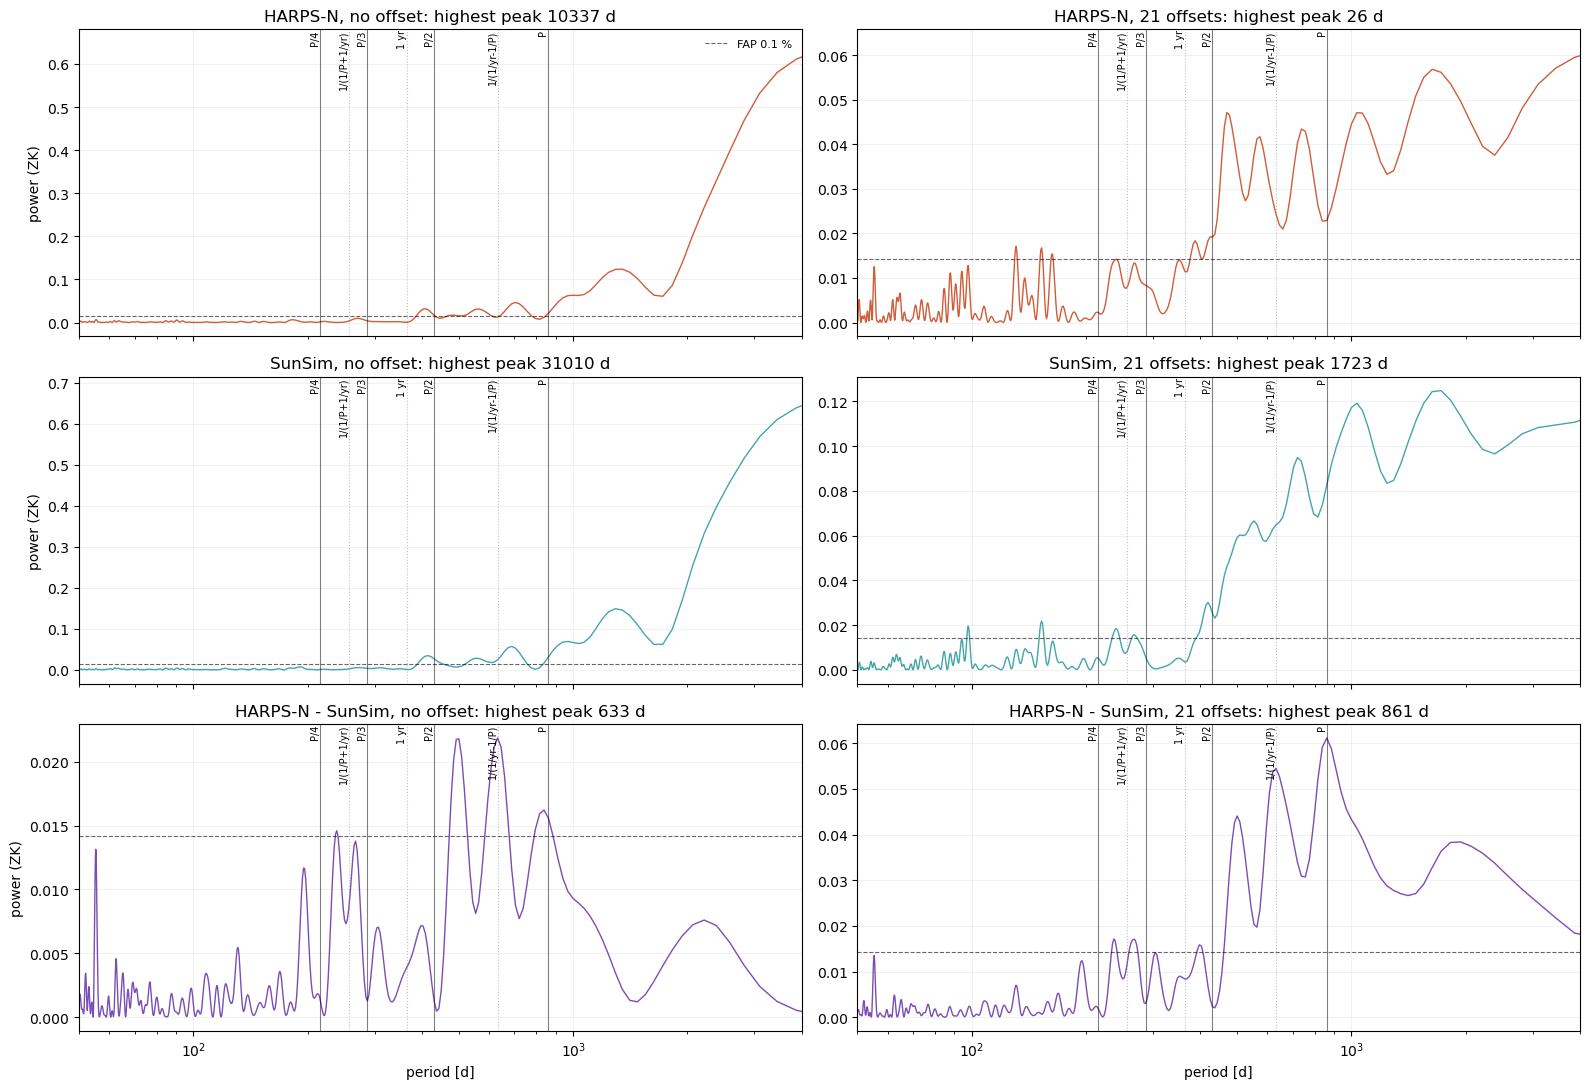

highest peak [d]  its amplitude [m/s]  P: peak [d]  \
series           offsets                                                       
HARPS-N          1                1.03e+04                   13          886   
                 21                   26.4                0.497          886   
SunSim           1                 3.1e+04                  116          886   
                 21               1.72e+03                 2.11          886   
HARPS-N - SunSim 1                     633                0.163          838   
                 21                    861                0.595          861   

                           P: FAP  P/2: peak [d]  P/2: FAP  P/3: peak [d]  \
series           offsets                                                    
HARPS-N          1        1.3e-12            413  8.54e-11            274   
                 21      1.06e-08            449  2.69e-10            274   
SunSim           1        1.7e-18            413  1.16e-12            274   
                 21      1.23e-38            419  1.33e-10            274   
HARPS-N - SunSim 1       0.000131            413     0.997            274   
                 21      1.88e-24            413    0.0577            274   

                          P/3: FAP  P/4: peak [d]  P/4: FAP  
series           offsets                                     
HARPS-N          1            0.15            222         1  
                 21         0.0269            225         1  
SunSim           1           0.998            222         1  
                 21        0.00261            214     0.999  
HARPS-N - SunSim 1           0.113            205         1  
                 21        0.00184            212         1

In [4]:
# periods marked: the peak P, its harmonics P/n, the yearly aliases 1/(1/P ± 1/yr) and 1 yr
marks = {'P': P_PEAK, **{'P/%d' % n: P_PEAK / n for n in HARMONICS},
         r'1/(1/P+1/yr)': 1 / (1 / P_PEAK + 1 / YEAR), r'1/(1/yr-1/P)': 1 / (1 / YEAR - 1 / P_PEAK), '1 yr': YEAR}
fig, axes = plt.subplots(len(SERIES), 2, figsize=(16, 11), sharex=True)
for row, s in zip(axes, SERIES):
    for ax, off in zip(row, (False, True)):
        ra, pg = models[s, off], pgs[s, off]
        ax.plot(1 / pg['freq'], pg['power'], color=COLORS[s], lw=1)
        ax.axhline(ra.power_level(1e-3), color='k', lw=0.8, ls='--', alpha=0.6, label='FAP 0.1 %')
        for name, p in marks.items():
            ax.axvline(p, color='0.5' if name.startswith('1') else 'k', lw=0.8, ls=':' if name.startswith('1') else '-',
                       alpha=0.5)
            ax.text(p, 1.0, name, rotation=90, fontsize=7, ha='right', va='top', transform=ax.get_xaxis_transform())
        ax.set_title('%s: highest peak %.0f d' % (ra.name, pg['P']))
        ax.set_xscale('log')
        ax.set_xlim(50, 4000)
        ax.grid(alpha=0.25, lw=0.5)
for ax in axes[:, 0]:
    ax.set_ylabel('power (ZK)')
for ax in axes[-1]:
    ax.set_xlabel('period [d]')
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

rows = []
for (s, off), ra in models.items():
    pg = pgs[s, off]
    row = {'series': SERIES[s], 'offsets': 21 if off else 1, 'highest peak [d]': pg['P'], 'its amplitude [m/s]': pg['amp']}
    for name, p in (('P', P_PEAK), *(('P/%d' % n, P_PEAK / n) for n in HARMONICS)):
        pk, pw = power_at(ra, pg, p)
        row['%s: peak [d]' % name], row['%s: FAP' % name] = pk, ra.fap(pw)
    rows.append(row)
table = pd.DataFrame(rows).set_index(['series', 'offsets'])
pd.options.display.float_format = '{:.3g}'.format
display(table)

## Harmonics: P fitted, periodogram of what is left

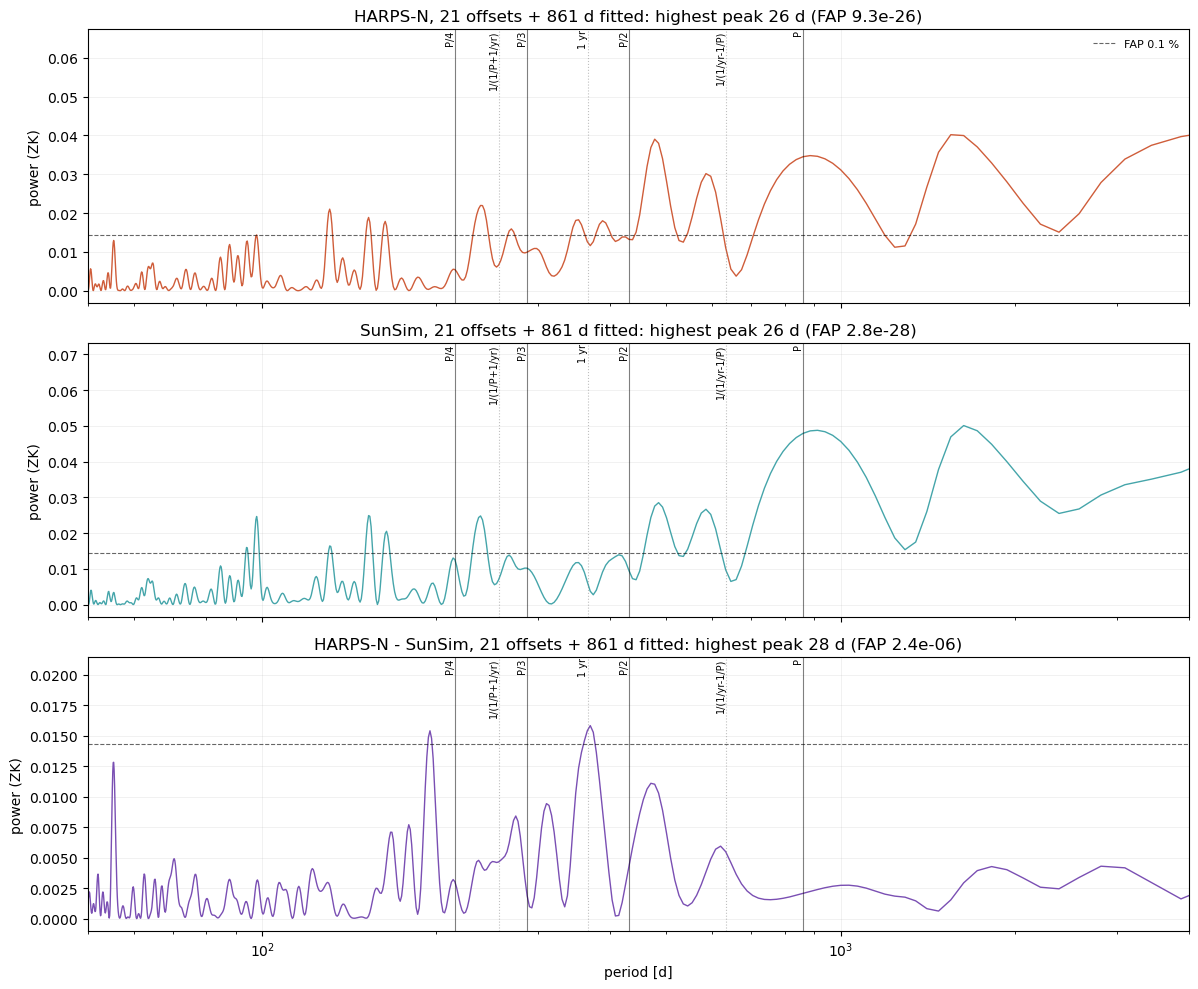

expected [d]  peak [d]   power      FAP
series           harmonic                                         
HARPS-N          P/2                430       449  0.0195 5.84e-06
                 P/3                287       274  0.0136  0.00207
                 P/4                215       214 0.00553    0.998
SunSim           P/2                430       413   0.014  0.00148
                 P/3                287       274  0.0108   0.0341
                 P/4                215       214  0.0131   0.0036
HARPS-N - SunSim P/2                430       449 0.00861    0.256
                 P/3                287       274 0.00841    0.303
                 P/4                215       214 0.00321        1

In [5]:
# the sinusoid of P_PEAK fitted with the offsets (fixed), then the GLS of the rest: power at the harmonics P/n
fig, axes = plt.subplots(len(SERIES), 1, figsize=(12, 10), sharex=True)
rows = []
for ax, s in zip(axes, SERIES):
    ra = analysis(s, True, fixed=(P_PEAK,))
    pg = ra.periodogram()
    ax.plot(1 / pg['freq'], pg['power'], color=COLORS[s], lw=1)
    ax.axhline(ra.power_level(1e-3), color='k', lw=0.8, ls='--', alpha=0.6, label='FAP 0.1 %')
    for name, p in marks.items():
        ax.axvline(p, color='0.5' if name.startswith('1') else 'k', lw=0.8, ls=':' if name.startswith('1') else '-', alpha=0.5)
        ax.text(p, 1.0, name, rotation=90, fontsize=7, ha='right', va='top', transform=ax.get_xaxis_transform())
    ax.set_title('%s, 21 offsets + %.0f d fitted: highest peak %.0f d (FAP %.1e)' % (SERIES[s], P_PEAK, pg['P'], pg['fap']))
    ax.set_ylabel('power (ZK)')
    ax.set_xscale('log')
    ax.set_xlim(50, 4000)
    ax.grid(alpha=0.25, lw=0.5)
    for n in HARMONICS:
        pk, pw = power_at(ra, pg, P_PEAK / n)
        rows.append({'series': SERIES[s], 'harmonic': 'P/%d' % n, 'expected [d]': P_PEAK / n, 'peak [d]': pk,
                     'power': pw, 'FAP': ra.fap(pw)})
axes[0].legend(frameon=False, fontsize=8)
axes[-1].set_xlabel('period [d]')
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).set_index(['series', 'harmonic']))

In [6]:
# joint least-squares fit: 21 offsets + P_PEAK and its harmonics; amplitude and its error (scatter of the residuals),
# and the BIC change when each harmonic is removed (> 0: the harmonic is needed)
def fit(y, groups, periods):
    g = np.unique(groups, return_inverse=True)[1]
    X = np.zeros((len(y), int(g.max()) + 1))
    X[np.arange(len(y)), g] = 1
    th = rv['t'] - rv['t'][0]
    X = np.hstack([X] + [np.column_stack([np.cos(2 * np.pi * th / P), np.sin(2 * np.pi * th / P)]) for P in periods])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    r = y - X @ beta
    s2 = r @ r / (len(y) - X.shape[1])
    cov = s2 * np.linalg.inv(X.T @ X)
    return beta, cov, r @ r, X.shape[1]


rows = []
periods = (P_PEAK,) + tuple(P_PEAK / n for n in HARMONICS)
for s in SERIES:
    y = np.asarray(rv[s], dtype=np.float64)
    beta, cov, rss, k = fit(y, rv['period'], periods)
    n_off = k - 2 * len(periods)
    for i, P in enumerate(periods):
        a, b = beta[n_off + 2 * i: n_off + 2 * i + 2]
        amp = np.hypot(a, b)
        J = np.array([a, b]) / amp
        err = np.sqrt(J @ cov[n_off + 2 * i: n_off + 2 * i + 2, n_off + 2 * i: n_off + 2 * i + 2] @ J)
        rss_without = fit(y, rv['period'], periods[:i] + periods[i + 1:])[2]
        dbic = len(y) * np.log(rss_without / rss) - 2 * np.log(len(y))
        rows.append({'series': SERIES[s], 'period [d]': P, 'K [m/s]': amp, 'error [m/s]': err, 'K / error': amp / err,
                     'BIC without it - with it': dbic})
pd.options.display.float_format = '{:.3f}'.format
display(pd.DataFrame(rows).set_index(['series', 'period [d]']))

K [m/s]  error [m/s]  K / error  \
series           period [d]                                    
HARPS-N          861.000       0.488        0.080      6.070   
                 430.500       0.418        0.074      5.633   
                 287.000       0.369        0.058      6.334   
                 215.250       0.223        0.054      4.145   
SunSim           861.000       1.016        0.088     11.525   
                 430.500       0.307        0.068      4.504   
                 287.000       0.349        0.054      6.492   
                 215.250       0.284        0.050      5.736   
HARPS-N - SunSim 861.000       0.667        0.063     10.653   
                 430.500       0.115        0.041      2.807   
                 287.000       0.032        0.032      0.996   
                 215.250       0.061        0.030      2.042   

                             BIC without it - with it  
series           period [d]                            
HARPS-N          861.000                       21.855  
                 430.500                       16.762  
                 287.000                       25.272  
                 215.250                        2.179  
SunSim           861.000                      136.307  
                 430.500                        5.299  
                 287.000                       27.329  
                 215.250                       17.937  
HARPS-N - SunSim 861.000                      113.940  
                 430.500                       -7.205  
                 287.000                      -14.176  
                 215.250                      -10.957

## Time series

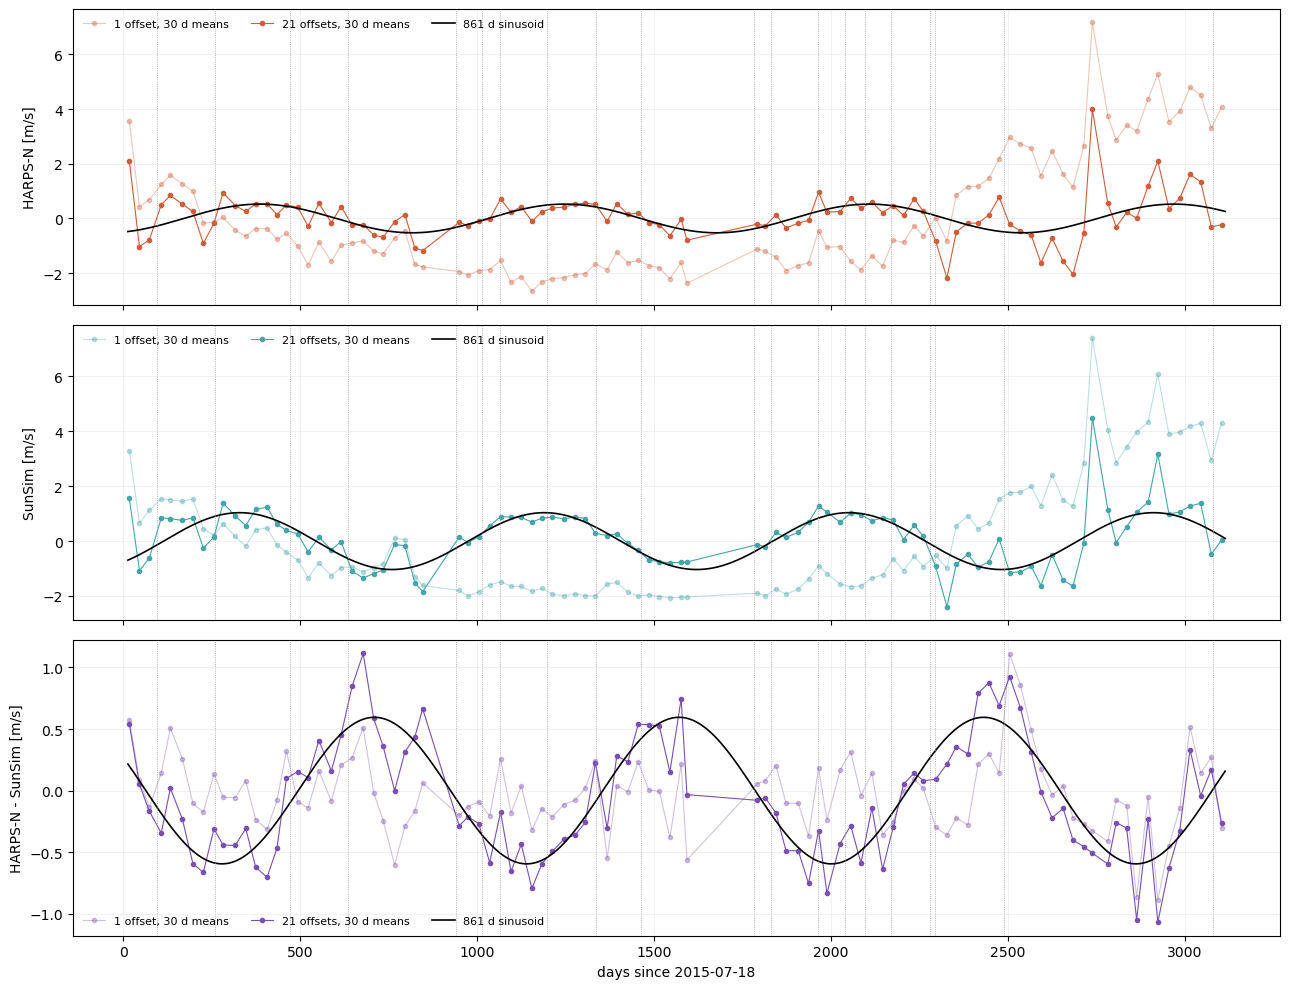

In [7]:
# every series minus its 21 offsets (fitted with the P_PEAK sinusoid), 30-day bins, and the fitted P_PEAK sinusoid
fig, axes = plt.subplots(len(SERIES), 1, figsize=(13, 10), sharex=True)
t = rv['t']
for ax, s in zip(axes, SERIES):
    y = np.asarray(rv[s], dtype=np.float64)
    for offsets, label, alpha in ((False, '1 offset', 0.35), (True, '21 offsets', 1.0)):
        groups = rv['period'] if offsets else np.zeros(len(t), int)
        beta, _, _, k = fit(y, groups, (P_PEAK,))
        n_off = k - 2
        g = np.unique(groups, return_inverse=True)[1]
        yo = y - beta[:n_off][g]
        bins = np.floor(t / 30)
        tb = pd.Series(t).groupby(bins).mean()
        yb = pd.Series(yo).groupby(bins).mean()
        ax.plot(tb, yb, 'o-', ms=3, lw=0.8, color=COLORS[s], alpha=alpha, label='%s, 30 d means' % label)
        if offsets:
            tt = np.linspace(t[0], t[-1], 2000)
            th = tt - t[0]
            ax.plot(tt, beta[n_off] * np.cos(2 * np.pi * th / P_PEAK) + beta[n_off + 1] * np.sin(2 * np.pi * th / P_PEAK),
                    color='k', lw=1.2, label='%.0f d sinusoid' % P_PEAK)
    for c in np.unique(rv['period'])[1:]:
        ax.axvline(t[rv['period'] == c][0], color='0.6', lw=0.6, ls=':')
    ax.set_ylabel('%s [m/s]' % SERIES[s])
    ax.grid(alpha=0.25, lw=0.5)
    ax.legend(frameon=False, fontsize=8, ncol=3)
axes[-1].set_xlabel('days since %s' % ORIGIN)
plt.tight_layout()
plt.show()

## The longest interval

longest interval: 584 d, 2022-05-11 to 2023-12-16


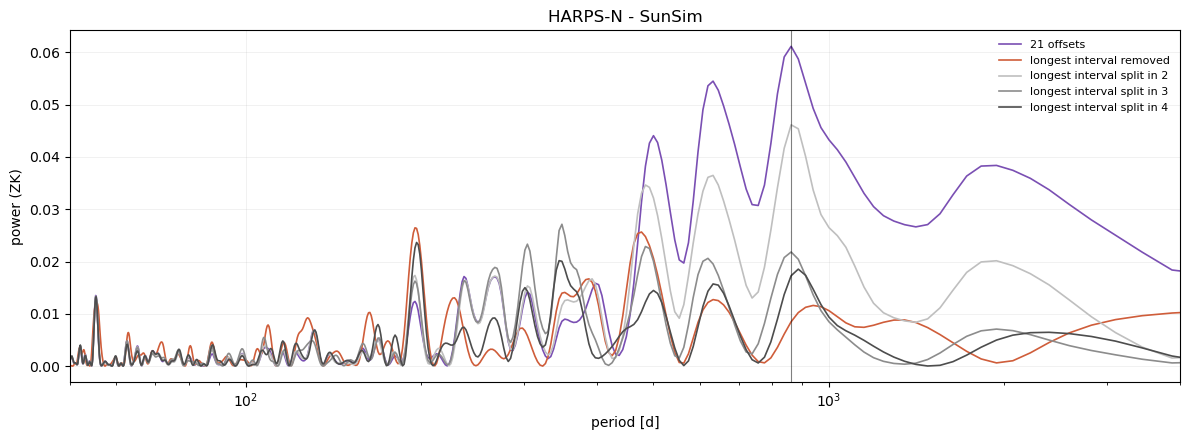

highest peak [d]  its FAP  \
case                        series                                        
21 offsets                  HARPS-N                       26.4    4e-25   
                            SunSim                    1.72e+03 2.46e-54   
                            HARPS-N - SunSim               861 1.88e-24   
longest interval removed    HARPS-N                       26.5 5.74e-15   
                            SunSim                        26.4 1.51e-16   
                            HARPS-N - SunSim               195 1.22e-06   
longest interval split in 2 HARPS-N                       26.4 1.33e-26   
                            SunSim                        26.4 2.75e-29   
                            HARPS-N - SunSim               861  1.1e-17   
longest interval split in 3 HARPS-N                       26.4 2.44e-26   
                            SunSim                        26.4 1.23e-28   
                            HARPS-N - SunSim               348  2.8e-09   
longest interval split in 4 HARPS-N                       26.4 1.63e-26   
                            SunSim                        26.4 4.36e-29   
                            HARPS-N - SunSim               196 9.44e-08   

                                              near P: peak [d]  near P: FAP  
case                        series                                           
21 offsets                  HARPS-N                        886     1.06e-08  
                            SunSim                         886     1.23e-38  
                            HARPS-N - SunSim               861     1.88e-24  
longest interval removed    HARPS-N                        886     6.76e-10  
                            SunSim                         886     2.22e-07  
                            HARPS-N - SunSim               886        0.374  
longest interval split in 2 HARPS-N                        838            1  
                            SunSim                         886      0.00111  
                            HARPS-N - SunSim               861      1.1e-17  
longest interval split in 3 HARPS-N                        886       0.0018  
                            SunSim                         886     0.000759  
                            HARPS-N - SunSim               861     5.77e-07  
longest interval split in 4 HARPS-N                        838            1  
                            SunSim                         886            1  
                            HARPS-N - SunSim               886     1.54e-05

In [8]:
# HARPS-N - SunSim with the 21 offsets: the longest interval (584 d) removed, or split into 2-4 intervals of equal length
p, t = np.asarray(rv['period']), np.asarray(rv['t'])
lengths = pd.Series({k: t[p == k].max() - t[p == k].min() for k in np.unique(p)})
longest = lengths.idxmax()
start = pd.Timestamp(ORIGIN)
print('longest interval: %.0f d, %s to %s' % (lengths[longest], (start + pd.Timedelta(days=t[p == longest].min())).date(),
                                             (start + pd.Timedelta(days=t[p == longest].max())).date()))
cases = {'21 offsets': (np.ones(len(t), bool), p), 'longest interval removed': (p != longest, p)}
for n_split in (2, 3, 4):
    g = p * 10
    inside = p == longest
    edges = np.linspace(t[inside].min(), t[inside].max() + 1e-6, n_split + 1)
    g[inside] = longest * 10 + np.digitize(t[inside], edges)
    cases['longest interval split in %d' % n_split] = (np.ones(len(t), bool), g)
fig, ax = plt.subplots(figsize=(12, 4.5))
rows = []
for (name, (keep, groups)), color in zip(cases.items(), ('#7a4fb3', '#cf5d3a', '0.75', '0.55', '0.3')):
    for s in SERIES:
        ra = OffsetAnalysis(t[keep], np.asarray(rv[s], dtype=np.float64)[keep], groups=groups[keep], fend=1 / 2.2)
        pg = ra.periodogram()
        pk, pw = power_at(ra, pg, P_PEAK)
        rows.append({'case': name, 'series': SERIES[s], 'highest peak [d]': pg['P'], 'its FAP': pg['fap'],
                     'near P: peak [d]': pk, 'near P: FAP': ra.fap(pw)})
        if s == 'res':
            ax.plot(1 / pg['freq'], pg['power'], color=color, lw=1.2, label=name)
ax.axvline(P_PEAK, color='k', lw=0.8, alpha=0.5)
ax.set_xscale('log')
ax.set_xlim(50, 4000)
ax.set_xlabel('period [d]')
ax.set_ylabel('power (ZK)')
ax.set_title('HARPS-N - SunSim')
ax.grid(alpha=0.25, lw=0.5)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
pd.options.display.float_format = '{:.3g}'.format
display(pd.DataFrame(rows).set_index(['case', 'series']))